Criação de amostragem

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configurações
rng = np.random.default_rng(42)

# População fictícia: 10.000 imóveis
n = 10_000

populacao = pd.DataFrame({
    "area_m2": rng.uniform(35, 200, n).round(),
    "dist_metro_km": rng.uniform(0.2, 15, n).round(1),
    "bairro": rng.choice(
        ["Centro", "Zona Sul", "Subúrbio"],
        n, p=[0.30, 0.30, 0.40]
    )
})

populacao["quartos"] = np.clip(
    (populacao["area_m2"] / 40 +
     rng.normal(0, 0.6, n)).round(), 1, 5
).astype(int)

efeito_bairro = populacao["bairro"].map({
    "Centro": 40,
    "Zona Sul": 90,
    "Subúrbio": 0
})

# Preço em milhares de reais
populacao["preco_mil"] = (
    60
    + 3.0 * populacao["area_m2"]
    + 12 * populacao["quartos"]
    - 8 * populacao["dist_metro_km"]
    + efeito_bairro
    + rng.normal(0, 35, n)
).round(2)

# Amostra aleatória de 200 imóveis
df = populacao.sample(n=200, random_state=42).copy()

print("População:", len(populacao))
print("Amostra:", len(df))
print("\nPrimeiros registros:")
display(df.head(10))


População: 10000
Amostra: 200

Primeiros registros:


,area_m2,dist_metro_km,bairro,quartos,preco_mil
6252,106.0,7.0,Centro,2,380.52
4684,199.0,6.0,Zona Sul,5,791.71
1731,43.0,5.8,Subúrbio,1,134.91
4742,164.0,11.6,Subúrbio,5,545.00
4521,103.0,4.7,Zona Sul,2,460.92
6340,179.0,8.1,Subúrbio,4,578.45
576,185.0,11.7,Zona Sul,4,677.61
5202,63.0,9.4,Subúrbio,2,177.09
6363,56.0,7.0,Zona Sul,2,317.18
439,139.0,6.4,Centro,2,500.42


## 2. Análise Exploratória de Dados (EDA)

### 2.1 Estatística descritiva

**Objetivo**

Investigar as características da amostra de 200 imóveis, utilizando medidas estatísticas para compreender a distribuição dos preços e identificar possíveis padrões e valores extremos.

**Metodologia**

Serão utilizadas medidas de tendência central (média e mediana), dispersão (desvio padrão) e posição (quartis), por meio do método `describe()` da biblioteca pandas.

A variável principal será `preco_mil`, que representa o preço dos imóveis em milhares de reais.

**Resultados e interpretação**

*A preencher após a execução do código e interpretação dos resultados.*

In [ ]:
# Estatísticas descritivas da variável preço
media = df["preco_mil"].mean()
moda = df["preco_mil"].mode()[0]
mediana = df["preco_mil"].median()
describe = df["preco_mil"].describe()

print(f"Descrição: {describe}")
print(f"Média: {media}")
print(f"Moda: {moda}")
print(f"Mediana: {mediana}")

Descrição: count    200.000000
mean     415.159400
std      170.535771
min       35.700000
25%      280.855000
50%      419.245000
75%      550.480000
max      810.660000
Name: preco_mil, dtype: float64
Média: 415.15939999999995
Moda: 35.7
Mediana: 419.245


In [ ]:
# Verificar quantas vezes cada preço aparece
df["preco_mil"].value_counts().head(10)

,count
preco_mil,
380.52,1
791.71,1
134.91,1
545.00,1
460.92,1
578.45,1
677.61,1
177.09,1
317.18,1


In [ ]:

# Frequência máxima de um preço
frequencia_maxima = df["preco_mil"].value_counts().max()

print(f"Maior frequência: {frequencia_maxima}")

if frequencia_maxima == 1:
    print("Não existe moda representativa: todos os preços são diferentes.")
else:
    print("Existe pelo menos um preço que se repete.")
    print(df["preco_mil"].mode())


Maior frequência: 1
Não existe moda representativa: todos os preços são diferentes.


### Análise da moda

A análise de frequência demonstrou que os 200 imóveis da amostra apresentam preços distintos, sem repetição de valores.

Portanto, a distribuição é considerada **amodal**, não havendo um preço predominante entre os valores observados.

Como a variável preço é quantitativa contínua, a análise de frequência por intervalos poderá ser mais informativa do que a moda dos valores individuais.

In [ ]:

# Coeficiente de variação dos preços
media = df["preco_mil"].mean()
desvio_padrao = df["preco_mil"].std()

cv = (desvio_padrao / media) * 100

print(f"Coeficiente de variação: {cv:.2f}%")


Coeficiente de variação: 41.08%


### 2.2 Análise de dispersão dos preços

Analisamos os preços de 200 imóveis para entender o quanto eles variam.

O preço médio encontrado foi de **R$ 415.159,40**, com um desvio padrão de **R$ 170.535,77**.

Calculamos também o coeficiente de variação (CV), que foi de **41,08%**. Isso mostra que os preços apresentam diferenças consideráveis em relação à média.

Essas diferenças podem estar relacionadas a características dos imóveis, como tamanho, localização e quantidade de quartos. Porém, ainda precisamos investigar essas relações antes de tirar conclusões.

**Conclusão:** os preços não estão todos próximos da média. Nossa próxima etapa será visualizar a distribuição para compreender melhor essas diferenças.


### 2.3 Distribuição dos preços dos imóveis

**Objetivo**

Analisar como os preços dos 200 imóveis estão distribuídos, identificando as faixas de preço mais frequentes e possíveis valores extremos.

**Metodologia**

Utilizaremos um histograma, que organiza os preços em intervalos e mostra quantos imóveis existem em cada faixa.

Essa visualização permitirá verificar se os preços estão concentrados em determinados valores ou se estão espalhados pela distribuição.

**Resultados e interpretação**

*A preencher após a análise do gráfico.*

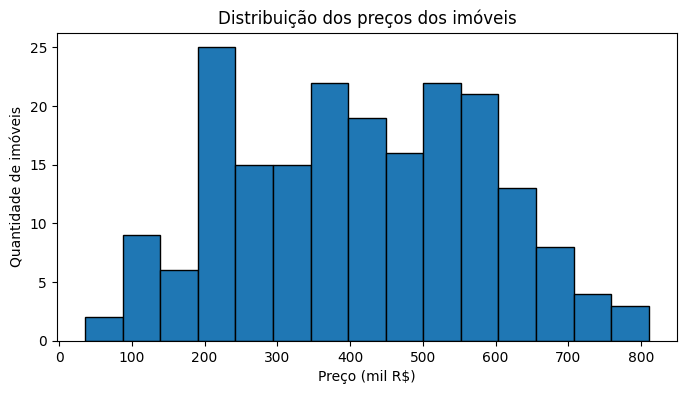

In [ ]:
# Histograma dos preços dos imóveis

plt.figure(figsize=(8, 4))

plt.hist(
    df["preco_mil"],
    bins=15,
    edgecolor="black"
)

plt.title("Distribuição dos preços dos imóveis")
plt.xlabel("Preço (mil R$)")
plt.ylabel("Quantidade de imóveis")

plt.show()

### 2.3 Distribuição dos preços dos imóveis

**Resultados e interpretação**

O histograma mostrou que a maior concentração de imóveis está na faixa aproximada de 190 mil a 242 mil, com cerca de 25 imóveis.

Os preços estão distribuídos por diferentes faixas, indicando uma variação considerável entre os imóveis analisados.

Essa observação reforça o resultado do coeficiente de variação de 41,08%, calculado anteriormente.

Visualmente, a distribuição não apresenta uma assimetria muito evidente. Para investigar melhor seu formato, será calculado o coeficiente de assimetria.

In [ ]:
# Calcular a assimetria dos preços
assimetria = df["preco_mil"].skew()

print(f"Assimetria: {assimetria:.3f}")

Assimetria: 0.046


### 2.3 Distribuição dos preços dos imóveis

**Objetivo**

Analisar como os preços dos 200 imóveis estão distribuídos, identificando as faixas de preço mais frequentes e possíveis valores extremos.

**Metodologia**

Foi utilizado um histograma com 15 intervalos para visualizar a distribuição dos preços. Também calculamos o coeficiente de assimetria para verificar se a distribuição apresenta uma cauda mais longa em alguma direção.

**Resultados e interpretação**

O histograma mostrou que a faixa entre aproximadamente 190 mil e 242 mil concentra a maior quantidade de imóveis, com cerca de 25 registros.

O coeficiente de assimetria encontrado foi de **0,046**, indicando uma distribuição aproximadamente simétrica, sem assimetria relevante.

Apesar disso, os preços apresentam uma dispersão considerável, conforme identificado anteriormente pelo coeficiente de variação de 41,08%.

**Conclusão**

Os preços apresentam grande variação, mas não demonstram uma assimetria significativa em sua distribuição. Isso significa que podemos ter uma distribuição aproximadamente simétrica e, ao mesmo tempo, bastante dispersa.